### *This file is for the quantification of cFos positive cells in striatal sections*

### *step 0: initialization*
In this step we load the functions we'll be using and assign some of them nicknames, as well as setting some constants if necessary. 

In [39]:
import sys
sys.path.insert(0, '..')

import math
import pandas as pd
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.font_manager import FontProperties
import seaborn as sns
import scipy.stats as stats
from statsmodels.stats.multitest import multipletests
import stereo_helpers as hp

# Style — load project-wide rcParams, then apply Illustrator-compatible font settings
mpl.rc_file('../matplotlibrc.txt')
mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['pdf.use14corefonts'] = True
sns.set_context('paper')
%matplotlib inline

mm = 1/25.4  # mm to inches

### *step 1: the loader*
In this step we'll load all the file types from the experiment for all subjects in the main directory.

In [40]:
all_data = hp.load_pickle('../data/cfos/fos_cell_counts_flat.pkl')

all_data.index.is_monotonic_increasing

True

### *step 2 & 3: filterring and formating*

filter the df and add columns for normalized intensity by subject-section combination, y_inverted, and x_flipped

In [41]:
# Remove rows where subject_id is 'neg1' and section_number is '003'
all_data = all_data[~((all_data['subject_id'] == 'neg1') & (all_data['section_number'] == '003'))].reset_index(drop=True)

In [42]:
all_data.head()

,subject_id,exp_group,section_number,cell_number,fos_count,fos_int_intensity,fos_mean_intensity,fos_median_intensity,x_location,y_location
0,c577m11,coc_30mgKg,001,1,0,7.788237,0.027716,0.027451,985.309609,45.355872
1,c577m11,coc_30mgKg,001,2,0,5.717648,0.027357,0.027451,1008.344498,42.875598
2,c577m11,coc_30mgKg,001,3,0,5.984314,0.018760,0.015686,952.868339,53.147335
3,c577m11,coc_30mgKg,001,4,0,4.317648,0.024814,0.023529,932.419540,58.390805
4,c577m11,coc_30mgKg,001,5,0,3.694118,0.018471,0.015686,896.010000,56.240000


In [43]:
# Group by 'subject_id' and 'section_number' and then invert the y-coordinates within each group
all_data['y_inverted'] = all_data.groupby(['subject_id', 'section_number'])['y_location'].transform(lambda y: y.max() - y)

# Create a new column for flipped x-coordinates with the original x-coordinates
all_data['x_inverted'] = all_data['x_location']

# Define the groups that require flipping the x-coordinate
flip_groups = {
    'c577m11': ['002', '004'],
    'neg1': ['004'],
    'wt1': ['004'],
    'wt3': ['005']
}

# Calculate the max x-coordinate for each group and flip the x-coordinates for the specified groups
for subject, sections in flip_groups.items():
    for section in sections:
        max_x = all_data[(all_data['subject_id'] == subject) & (all_data['section_number'] == section)]['x_location'].max()
        all_data.loc[(all_data['subject_id'] == subject) & (all_data['section_number'] == section), 'x_inverted'] = max_x - all_data['x_inverted']

# Calculate the median x and y coordinates for each subject-section group
medians = all_data.groupby(['subject_id', 'section_number']).agg({'x_inverted': 'median', 'y_inverted': 'median'})
medians = medians.rename(columns={'x_inverted': 'mid_x', 'y_inverted': 'mid_y'})

# Merge the median values back into the original dataframe
all_data = all_data.merge(medians, on=['subject_id', 'section_number'])

# Divide each section into 4 quadrants using median x/y as the crosshair
conditions = [
    (all_data['x_inverted'] >= all_data['mid_x']) & (all_data['y_inverted'] <= all_data['mid_y']),
    (all_data['x_inverted'] >= all_data['mid_x']) & (all_data['y_inverted'] > all_data['mid_y']),
    (all_data['x_inverted'] < all_data['mid_x']) & (all_data['y_inverted'] > all_data['mid_y']),
    (all_data['x_inverted'] < all_data['mid_x']) & (all_data['y_inverted'] <= all_data['mid_y'])
]
regions = ['vls', 'dls', 'dms', 'vms']
all_data['region'] = np.select(conditions, regions)
all_data.drop(columns=['mid_x', 'mid_y'], inplace=True)

In [44]:
fos_data = all_data.copy()

# Zero the intensity where fos_count is 0; treat fos_count > 1 as 0 (segmentation artefacts)
fos_data.loc[fos_data['fos_count'] == 0, 'fos_int_intensity'] = 0
fos_data.loc[fos_data['fos_count'] > 1, 'fos_count'] = 0

# Normalize intensity per subject by that subject's max intensity
max_intensity_by_group = fos_data.groupby('subject_id')['fos_int_intensity'].transform('max')
fos_data['normalized_intensity'] = fos_data['fos_int_intensity'] / max_intensity_by_group

### *step 4 & 5: computations and visualizations*

##### **4a & 5a: cfos visualization on striatal cells, and intensity spectrum**

5a: plot the all cells and cfos positive cells in scatter plots

C:\Users\Ben\AppData\Local\Temp\ipykernel_22984\1215697443.py:24: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  _base_cmap = plt.cm.get_cmap('YlOrBr')
c:\Users\Ben\anaconda3\envs\myenv\lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
c:\Users\Ben\anaconda3\envs\myenv\lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
c:\Users\Ben\anaconda3\envs\myenv\lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecate

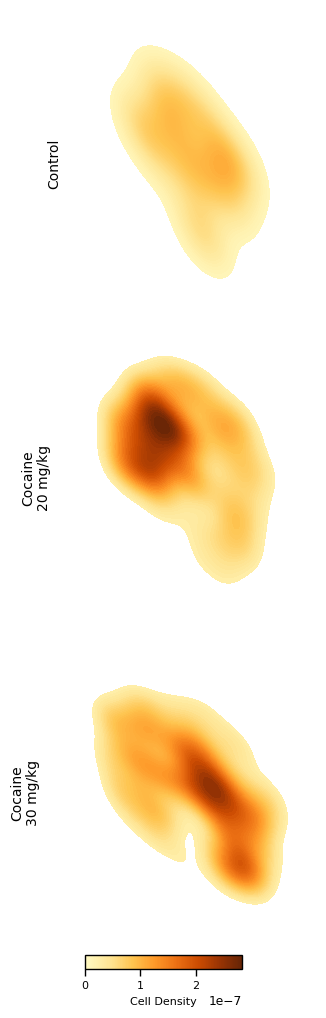

In [45]:
# ── NORMALIZATION MODE ────────────────────────────────────────────────────────
# Toggle this flag to switch between two interpretations:
#
#   False  →  PER-PLOT  (default): seaborn auto-scales each panel to its own
#             density range. All groups are equally legible regardless of how
#             many cells they contain.
#             Use for: WHERE do cells localize? (spatial pattern question)
#
#   True   →  GLOBAL: all panels share one scale anchored to the densest
#             section. Sparse sections (e.g. control) appear pale.
#             Use for: HOW MANY cells? (magnitude / induction question)
# ─────────────────────────────────────────────────────────────────────────────
NORMALIZE_GLOBALLY = True

# ── COLORMAP OFFSET ───────────────────────────────────────────────────────────
#   0.00  = standard YlOrBr (zero density is white)
#   0.10  = light cream at zero (recommended)
#   0.15  = pale yellow at zero
CMAP_OFFSET = 0.10

from matplotlib.colors import Normalize, LinearSegmentedColormap
from scipy.stats import gaussian_kde as sp_kde

_base_cmap = plt.cm.get_cmap('YlOrBr')
cmap_plot = LinearSegmentedColormap.from_list(
    'YlOrBr_offset', _base_cmap(np.linspace(CMAP_OFFSET, 1.0, 256))
)

plot_specs = [
    {'subject_id': 'neg1',   'section_number': '006', 'label': 'Control'},
    {'subject_id': 'c577m3', 'section_number': '003', 'label': 'Cocaine\n20 mg/kg'},
    {'subject_id': 'wt3',    'section_number': '003', 'label': 'Cocaine\n30 mg/kg'},
]

# Filter to only the specified (subject, section) pairs, cFos+ cells only
valid_pairs = {(s['subject_id'], s['section_number']) for s in plot_specs}
pair_mask = pd.MultiIndex.from_arrays(
    [fos_data['subject_id'], fos_data['section_number']]
).isin(valid_pairs)
filtered_data = fos_data[pair_mask & (fos_data['fos_count'] == 1)].copy()

# ── Compute peak densities via scipy KDE (Scott bandwidth = seaborn default) ─
# Needed for global mode. Also used to build the ScalarMappable for the colorbar.
peak_densities = []
for spec in plot_specs:
    subset = filtered_data[
        (filtered_data['subject_id']    == spec['subject_id']) &
        (filtered_data['section_number'] == spec['section_number'])
    ][['x_inverted', 'y_inverted']].dropna()
    if len(subset) > 1:
        kde = sp_kde(subset.values.T)
        peak_densities.append(kde(subset.values.T).max())

global_max = max(peak_densities)

# ── Set norm and colorbar label based on mode ─────────────────────────────────
if NORMALIZE_GLOBALLY:
    # Shared scale — magnitudes are comparable across panels
    shared_norm = Normalize(vmin=0, vmax=global_max)
    cbar_label  = 'Cell Density'
else:
    # Per-plot — each panel scaled independently; magnitudes are NOT comparable
    shared_norm = None
    cbar_label  = 'Density (per section, a.u.)'

# ── Plot ──────────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(len(plot_specs), 1,
                         figsize=(80 * mm, len(plot_specs) * 80 * mm),
                         constrained_layout=True)

for ax, spec in zip(axes, plot_specs):
    subset = filtered_data[
        (filtered_data['subject_id']    == spec['subject_id']) &
        (filtered_data['section_number'] == spec['section_number'])
    ]
    sns.kdeplot(
        x=subset['x_inverted'], y=subset['y_inverted'],
        fill=True, cmap=cmap_plot, levels=50,
        ax=ax,
        norm=shared_norm   # None → per-plot auto-scale; Normalize(...) → global
    )
    ax.set_aspect('equal', adjustable='box')
    ax.axis('off')
    ax.annotate(
        spec['label'],
        xy=(-0.15, 0.5), xycoords='axes fraction',
        fontsize=10, ha='center', va='center', rotation=90
    )

# ── Horizontal colorbar below ─────────────────────────────────────────────────
# In global mode: ticks reflect actual density values (comparable across panels).
# In per-plot mode: decorative only — ticks show low/high since each panel has its own scale.
cbar_norm = shared_norm if NORMALIZE_GLOBALLY else Normalize(vmin=0, vmax=1)
sm = plt.cm.ScalarMappable(cmap=cmap_plot, norm=cbar_norm)
sm.set_array([])
cbar_ax = fig.add_axes([0.25, -0.02, 0.5, 0.015])
cbar = fig.colorbar(sm, cax=cbar_ax, orientation='horizontal')
cbar.set_label(cbar_label, fontsize=8)
cbar.ax.tick_params(labelsize=8)
if not NORMALIZE_GLOBALLY:
    cbar.set_ticks([0, 1])
    cbar.set_ticklabels(['low', 'high'])

fig_path = '../output/cFos/cfos_density_map_by_group'
fig.savefig(f'{fig_path}.pdf', dpi=300, bbox_inches='tight')
fig.savefig(f'{fig_path}.png', dpi=300, bbox_inches='tight')
plt.show()

c:\Users\Ben\anaconda3\envs\myenv\lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
c:\Users\Ben\anaconda3\envs\myenv\lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
c:\Users\Ben\anaconda3\envs\myenv\lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
c:\Users\Ben\anaconda3\envs\myenv\lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Conver

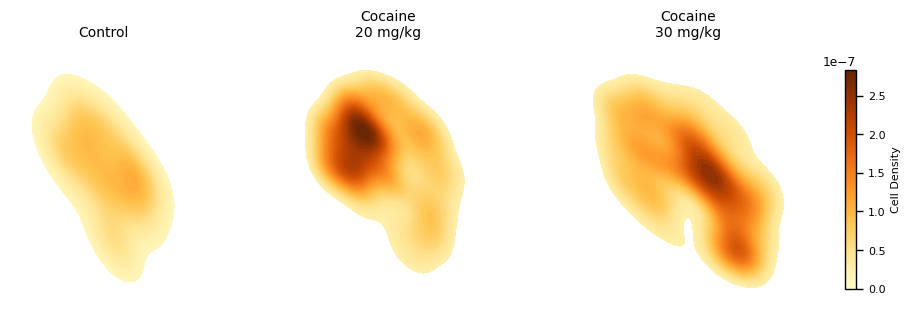

In [46]:
# 2D KDE density map — horizontal layout (1×3), labels on top, colorbar on right
# Reads NORMALIZE_GLOBALLY, shared_norm, cbar_label, and cmap_plot from the cell above.
# To switch modes or adjust the colormap offset, change those settings there and re-run both cells.

fig, axes = plt.subplots(1, len(plot_specs),
                         figsize=(len(plot_specs) * 80 * mm, 80 * mm),
                         constrained_layout=True)

for ax, spec in zip(axes, plot_specs):
    subset = filtered_data[
        (filtered_data['subject_id']    == spec['subject_id']) &
        (filtered_data['section_number'] == spec['section_number'])
    ]
    sns.kdeplot(
        x=subset['x_inverted'], y=subset['y_inverted'],
        fill=True, cmap=cmap_plot, levels=50,
        ax=ax,
        norm=shared_norm   # None → per-plot auto-scale; Normalize(...) → global
    )
    ax.set_aspect('equal', adjustable='box')
    ax.axis('off')
    ax.set_title(spec['label'], fontsize=10, pad=4)

# ── Vertical colorbar on the right ───────────────────────────────────────────
# In global mode: ticks reflect actual density values (comparable across panels).
# In per-plot mode: decorative only — ticks show low/high since each panel has its own scale.
cbar_norm = shared_norm if NORMALIZE_GLOBALLY else Normalize(vmin=0, vmax=1)
sm = plt.cm.ScalarMappable(cmap=cmap_plot, norm=cbar_norm)
sm.set_array([])
cbar = fig.colorbar(sm, ax=axes[-1], fraction=0.046, pad=0.04, shrink=0.8,
                    orientation='vertical')
cbar.set_label(cbar_label, fontsize=8)
cbar.ax.tick_params(labelsize=8)
if not NORMALIZE_GLOBALLY:
    cbar.set_ticks([0, 1])
    cbar.set_ticklabels(['low', 'high'])

fig_path = '../output/cFos/cfos_density_map_by_group_horizontal'
fig.savefig(f'{fig_path}.pdf', dpi=300, bbox_inches='tight')
fig.savefig(f'{fig_path}.png', dpi=300, bbox_inches='tight')
plt.show()

C:\Users\Ben\AppData\Local\Temp\ipykernel_22984\2505985659.py:41: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  _base_cmap_p = plt.cm.get_cmap('YlOrBr')
c:\Users\Ben\anaconda3\envs\myenv\lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
c:\Users\Ben\anaconda3\envs\myenv\lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
c:\Users\Ben\anaconda3\envs\myenv\lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is depreca

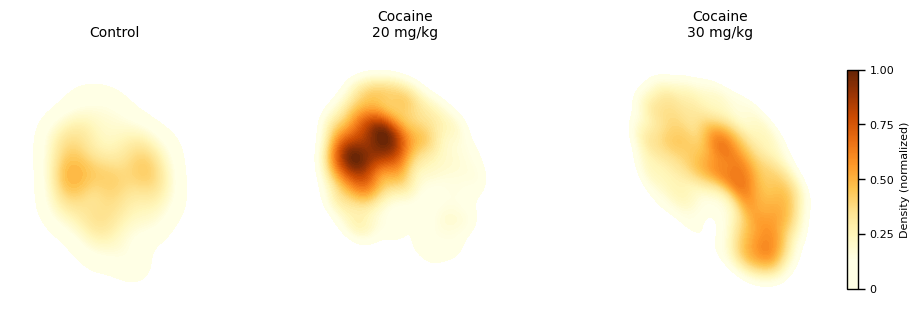

In [47]:
# 2D KDE density map — POOLED sections per subject (horizontal 1×3 layout)
#
# ── What this cell does (and why it differs from the per-section cells above) ─
# The two cells above each show ONE representative section per group.
# This cell pools cFos+ cells from ALL sections of each subject into a single
# KDE. The result is an aggregate spatial density map across the full
# anterior-posterior tissue volume sampled for that animal.
#
# This replicates the approach from the original notebook
# (STEREO_fig1_cFosAnalysis.ipynb, cell-26/27), where the second plotting pass
# inadvertently filtered by subject_id only (omitting section_number), causing
# all sections to be pooled. The effect is visible: the cocaine 30 mg/kg panel
# shows a very concentrated dark cluster because high-density zones are
# consistent across sections and reinforce each other when pooled.
#
# Caveat: sections differ in anterior-posterior position, so pooling conflates
# spatial variation within a section with variation across sections. Use
# alongside the per-section view, not as a replacement.
#
# Requires: sp_kde, Normalize, LinearSegmentedColormap (imported in cell 339269b7 above)
#           fos_data (defined in preprocessing cells above)

# ── NORMALIZATION MODE ────────────────────────────────────────────────────────
#   True  →  GLOBAL (default): all subjects share one density scale.
#             Sparse subjects (e.g. control) appear pale — reflects true
#             difference in total cFos+ cell number across groups.
#             Use for: comparing HOW MANY and WHERE simultaneously.
#
#   False →  PER-SUBJECT: each subject auto-scaled to its own pooled density.
#             All subjects appear equally saturated — spatial pattern only.
#             Use for: comparing WHERE cells cluster regardless of total count.
# ─────────────────────────────────────────────────────────────────────────────
NORMALIZE_GLOBALLY_POOLED = True

# ── COLORMAP OFFSET ───────────────────────────────────────────────────────────
#   0.00  = standard YlOrBr (zero density is white)
#   0.10  = light cream at zero (recommended)
#   0.15  = pale yellow at zero
CMAP_OFFSET_POOLED = -0.15

_base_cmap_p = plt.cm.get_cmap('YlOrBr')
cmap_plot_pooled = LinearSegmentedColormap.from_list(
    'YlOrBr_offset_pooled', _base_cmap_p(np.linspace(CMAP_OFFSET_POOLED, 1.0, 256))
)

# Same three representative subjects as the per-section cells
plot_specs_pooled = [
    {'subject_id': 'neg1',   'label': 'Control'},
    {'subject_id': 'c577m3', 'label': 'Cocaine\n20 mg/kg'},
    {'subject_id': 'wt3',    'label': 'Cocaine\n30 mg/kg'},
]

# ── Pool ALL sections — no section_number filter (intentional) ────────────────
pooled_data = fos_data[
    fos_data['subject_id'].isin([s['subject_id'] for s in plot_specs_pooled]) &
    (fos_data['fos_count'] == 1)
].copy()

# ── Compute peak densities via scipy KDE (Scott bandwidth = seaborn default) ─
peak_densities_pooled = []
for spec in plot_specs_pooled:
    subset = pooled_data[
        pooled_data['subject_id'] == spec['subject_id']
    ][['x_inverted', 'y_inverted']].dropna()
    if len(subset) > 1:
        kde = sp_kde(subset.values.T)
        peak_densities_pooled.append(kde(subset.values.T).max())

global_max_pooled = max(peak_densities_pooled)

# ── Set norm and colorbar label based on mode ─────────────────────────────────
if NORMALIZE_GLOBALLY_POOLED:
    shared_norm_pooled = Normalize(vmin=0, vmax=global_max_pooled)
    cbar_label_pooled  = 'Density (normalized)'
else:
    shared_norm_pooled = None
    cbar_label_pooled  = 'Density (per subject, a.u.)'

# ── Plot — horizontal 1×3 layout ──────────────────────────────────────────────
fig, axes = plt.subplots(1, len(plot_specs_pooled),
                         figsize=(len(plot_specs_pooled) * 80 * mm, 80 * mm),
                         constrained_layout=True)

for ax, spec in zip(axes, plot_specs_pooled):
    subset = pooled_data[pooled_data['subject_id'] == spec['subject_id']]
    sns.kdeplot(
        x=subset['x_inverted'], y=subset['y_inverted'],
        fill=True, cmap=cmap_plot_pooled, levels=50,
        ax=ax,
        norm=shared_norm_pooled
    )
    ax.set_aspect('equal', adjustable='box')
    ax.axis('off')
    ax.set_title(spec['label'], fontsize=10, pad=4)

# ── Vertical colorbar on the right ────────────────────────────────────────────
# Global mode: ticks are placed at 0/25/50/75/100% of global_max_pooled but
# labelled as 0.00/0.25/0.50/0.75/1.00, replicating the original notebook's
# 0-1.00 colorbar (where internal KDE scale happened to be [0,1]).
cbar_norm_pooled = shared_norm_pooled if NORMALIZE_GLOBALLY_POOLED else Normalize(vmin=0, vmax=1)
sm = plt.cm.ScalarMappable(cmap=cmap_plot_pooled, norm=cbar_norm_pooled)
sm.set_array([])
cbar = fig.colorbar(sm, ax=axes[-1], fraction=0.046, pad=0.04, shrink=0.8,
                    orientation='vertical')
cbar.set_label(cbar_label_pooled, fontsize=8)
cbar.ax.tick_params(labelsize=8)
if NORMALIZE_GLOBALLY_POOLED:
    cbar.set_ticks([0,
                    global_max_pooled * 0.25,
                    global_max_pooled * 0.50,
                    global_max_pooled * 0.75,
                    global_max_pooled])
    cbar.set_ticklabels(['0', '0.25', '0.50', '0.75', '1.00'])
else:
    cbar.set_ticks([0, 1])
    cbar.set_ticklabels(['low', 'high'])

fig_path = '../output/cFos/cfos_density_map_pooled_sections'
fig.savefig(f'{fig_path}.pdf', dpi=300, bbox_inches='tight')
fig.savefig(f'{fig_path}.png', dpi=300, bbox_inches='tight')
plt.show()

In [ ]:
# 2D KDE density map — POOLED across BOTH mice AND all sections per GROUP
#
# ── What this cell does (and how it differs from the cell above) ──────────────
# The cell above pools all sections of a SINGLE representative mouse per group.
# This cell pools cFos+ cells from BOTH mice in each dose group, across ALL of
# their sections, into one KDE per group — a true "across mice and sections"
# aggregate spatial density map for each condition:
#
#     control    = neg1   + wt1     (all sections)
#     coc_20mgKg = c577m3 + wt2     (all sections)
#     coc_30mgKg = c577m11 + wt3    (all sections)
#
# Caveat: cells are pooled RAW, so a mouse (or section) with more cFos+ cells
# contributes proportionally more weight to its group's KDE. Section/animal
# coordinate frames are overlaid without atlas registration, so this conflates
# within-section spatial pattern with across-section and across-animal variation.
# Use as a qualitative aggregate, alongside the per-section / per-subject views.
#
# Depends on: fos_data (preprocessing cells above). Imports needed helpers itself.

from matplotlib.colors import Normalize, LinearSegmentedColormap
from scipy.stats import gaussian_kde as sp_kde

# ── NORMALIZATION MODE ────────────────────────────────────────────────────────
#   True  →  GLOBAL (default): all groups share one density scale (magnitudes
#            comparable across panels).
#   False →  PER-GROUP: each group auto-scaled to its own pooled density
#            (spatial pattern only).
NORMALIZE_GLOBALLY_GROUP = True

# Colormap offset (matches the pooled-sections cell above)
CMAP_OFFSET_GROUP = -0.15
_base_cmap_g = plt.cm.get_cmap('YlOrBr')
cmap_plot_group = LinearSegmentedColormap.from_list(
    'YlOrBr_offset_group', _base_cmap_g(np.linspace(CMAP_OFFSET_GROUP, 1.0, 256))
)

# Groups defined by exp_group → pools ALL mice + ALL sections in each group
group_specs = [
    {'exp_group': 'control',    'label': 'Control'},
    {'exp_group': 'coc_20mgKg', 'label': 'Cocaine\n20 mg/kg'},
    {'exp_group': 'coc_30mgKg', 'label': 'Cocaine\n30 mg/kg'},
]

# All cFos+ cells (no subject/section filter — pooling is intentional)
grouped_data = fos_data[fos_data['fos_count'] == 1].copy()

# ── Peak densities per group (for global normalization) ───────────────────────
peak_densities_group = []
for spec in group_specs:
    subset = grouped_data[grouped_data['exp_group'] == spec['exp_group']][
        ['x_inverted', 'y_inverted']].dropna()
    if len(subset) > 1:
        kde = sp_kde(subset.values.T)
        peak_densities_group.append(kde(subset.values.T).max())
global_max_group = max(peak_densities_group)

if NORMALIZE_GLOBALLY_GROUP:
    shared_norm_group = Normalize(vmin=0, vmax=global_max_group)
    cbar_label_group  = 'Density (normalized)'
else:
    shared_norm_group = None
    cbar_label_group  = 'Density (per group, a.u.)'

# ── Plot — horizontal 1×3 layout ──────────────────────────────────────────────
fig, axes = plt.subplots(1, len(group_specs),
                         figsize=(len(group_specs) * 80 * mm, 80 * mm),
                         constrained_layout=True)

for ax, spec in zip(axes, group_specs):
    subset = grouped_data[grouped_data['exp_group'] == spec['exp_group']]
    n_mice = subset['subject_id'].nunique()
    sns.kdeplot(
        x=subset['x_inverted'], y=subset['y_inverted'],
        fill=True, cmap=cmap_plot_group, levels=50,
        ax=ax,
        norm=shared_norm_group
    )
    ax.set_aspect('equal', adjustable='box')
    ax.axis('off')
    ax.set_title(f"{spec['label']}\n(n={n_mice} mice)", fontsize=10, pad=4)

# ── Vertical colorbar on the right ────────────────────────────────────────────
cbar_norm_group = shared_norm_group if NORMALIZE_GLOBALLY_GROUP else Normalize(vmin=0, vmax=1)
sm = plt.cm.ScalarMappable(cmap=cmap_plot_group, norm=cbar_norm_group)
sm.set_array([])
cbar = fig.colorbar(sm, ax=axes[-1], fraction=0.046, pad=0.04, shrink=0.8,
                    orientation='vertical')
cbar.set_label(cbar_label_group, fontsize=8)
cbar.ax.tick_params(labelsize=8)
if NORMALIZE_GLOBALLY_GROUP:
    cbar.set_ticks([0,
                    global_max_group * 0.25,
                    global_max_group * 0.50,
                    global_max_group * 0.75,
                    global_max_group])
    cbar.set_ticklabels(['0', '0.25', '0.50', '0.75', '1.00'])
else:
    cbar.set_ticks([0, 1])
    cbar.set_ticklabels(['low', 'high'])

fig_path = '../output/cFos/cfos_density_map_pooled_mice_and_sections'
fig.savefig(f'{fig_path}.pdf', dpi=300, bbox_inches='tight')
fig.savefig(f'{fig_path}.png', dpi=300, bbox_inches='tight')
plt.show()

# ── Report composition of each pooled group ───────────────────────────────────
for spec in group_specs:
    subset = grouped_data[grouped_data['exp_group'] == spec['exp_group']]
    mice = sorted(subset['subject_id'].unique())
    print(f"{spec['exp_group']}: mice={mice}, "
          f"sections/mouse pooled, n cFos+ cells={len(subset)}")


##### **4b and 5b: fraction of cfos+ cells per region**

calculate fraction of cells that are cfos positive in each of the striatal region:

In [48]:
# Fraction of cFos+ cells per subject / section / region
positive_counts = fos_data[fos_data['fos_count'] == 1].groupby(
    ['subject_id', 'exp_group', 'section_number', 'region']
).size().reset_index(name='positive_cell_count')

total_counts = fos_data.groupby(
    ['subject_id', 'exp_group', 'section_number']
).size().reset_index(name='total_cell_count')

merged_df = pd.merge(positive_counts, total_counts, on=['subject_id', 'exp_group', 'section_number'])
merged_df['fraction'] = merged_df['positive_cell_count'] / merged_df['total_cell_count']

print(merged_df[['subject_id', 'exp_group', 'section_number', 'region', 'fraction']])

    subject_id   exp_group section_number region  fraction
0      c577m11  coc_30mgKg            001    dls  0.020874
1      c577m11  coc_30mgKg            001    dms  0.045049
2      c577m11  coc_30mgKg            001    vls  0.024563
3      c577m11  coc_30mgKg            001    vms  0.013883
4      c577m11  coc_30mgKg            002    dls  0.021001
..         ...         ...            ...    ...       ...
106        wt3  coc_30mgKg            005    vms  0.007201
107        wt3  coc_30mgKg            006    dls  0.017566
108        wt3  coc_30mgKg            006    dms  0.033974
109        wt3  coc_30mgKg            006    vls  0.048934
110        wt3  coc_30mgKg            006    vms  0.005694

[111 rows x 5 columns]


c:\Users\Ben\anaconda3\envs\myenv\lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
c:\Users\Ben\anaconda3\envs\myenv\lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
C:\Users\Ben\AppData\Local\Temp\ipykernel_22984\2969180181.py:23: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.pointplot(
c:\Users\Ben\anaconda3\envs\myenv\lib\site-packages\seaborn\categorical.py:1728: UserWarning: You passed a edgecolor/edgecolors ((0.1477136475930195, 0.14772002848141771, 0.1476949000552352)) for an unfilled marker ('_').  Matplotlib is ignoring the edgecolor in favor of th

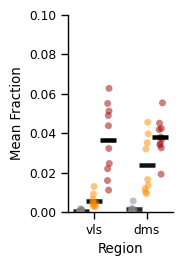

In [49]:
# Only keep VLS and DMS
region_order = ['vls', 'dms']
exp_group_order = ['control', 'coc_20mgKg', 'coc_30mgKg']

# Custom palette with requested colors
palette = {'control': '#808080', 'coc_20mgKg': '#ff8c00', 'coc_30mgKg': '#990000'}

width_in = 34.362 * mm
height_in = 65 * mm
plt.figure(figsize=(width_in, height_in))

# Filter merged_df for only VLS and DMS
plot_df = merged_df[merged_df['region'].isin(region_order)]

# Strip plot
sns.stripplot(
    data=plot_df, x='region', y='fraction', hue='exp_group',
    order=region_order, hue_order=exp_group_order, palette=palette,
    dodge=True, jitter=True, marker='o', alpha=0.5, size=5
)

# Point plot (mean)
sns.pointplot(
    data=plot_df, x='region', y='fraction', hue='exp_group',
    order=region_order, hue_order=exp_group_order,
    dodge=0.5, join=False, markers='_', ci=None, color='black', scale=2.0
)

# Remove legend
plt.legend([], [], frameon=False)

# Labels and formatting
plt.ylim(0, 0.1)
plt.xlabel('Region')
plt.ylabel('Mean Fraction')
sns.despine()

fig_path = '../output/cFos/mean_fraction_by_region_and_exp_group'
plt.savefig(f'{fig_path}.pdf', dpi=300, bbox_inches='tight')
plt.savefig(f'{fig_path}.png', dpi=300, bbox_inches='tight')
plt.show()

c:\Users\Ben\anaconda3\envs\myenv\lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
c:\Users\Ben\anaconda3\envs\myenv\lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
C:\Users\Ben\AppData\Local\Temp\ipykernel_22984\1028795602.py:11: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.pointplot(
c:\Users\Ben\anaconda3\envs\myenv\lib\site-packages\seaborn\categorical.py:1728: UserWarning: You passed a edgecolor/edgecolors ((0.1477136475930195, 0.14772002848141771, 0.1476949000552352)) for an unfilled marker ('_').  Matplotlib is ignoring the edgecolor in favor of th

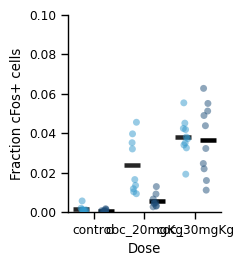

In [50]:
# Strip plot — alternative: x = dose, hue = region
region_palette = {'vls': '#1f4e79', 'dms': '#3399cc'}
region_order_alt = ['dms', 'vls']

plt.figure(figsize=(50 * mm, 65 * mm))
sns.stripplot(
    data=plot_df, x='exp_group', y='fraction', hue='region',
    order=exp_group_order, hue_order=region_order_alt, palette=region_palette,
    dodge=True, jitter=True, marker='o', alpha=0.5, size=5
)
sns.pointplot(
    data=plot_df, x='exp_group', y='fraction', hue='region',
    order=exp_group_order, hue_order=region_order_alt,
    dodge=0.5, join=False, markers='_', ci=None, color='black', scale=2.0
)
plt.legend([], [], frameon=False)
plt.ylim(0, 0.1)
plt.xlabel('Dose')
plt.ylabel('Fraction cFos+ cells')
sns.despine()

fig_path = '../output/cFos/mean_fraction_by_dose_and_region'
plt.savefig(f'{fig_path}.pdf', dpi=300, bbox_inches='tight')
plt.savefig(f'{fig_path}.png', dpi=300, bbox_inches='tight')
plt.show()

In [51]:
merged_df['subject_id'].unique()

array(['c577m11', 'c577m3', 'neg1', 'wt1', 'wt2', 'wt3'], dtype=object)

In [52]:
# Statistical comparison of mean fractions between groups for each region (non-parametric tests)
region_order = ['vls', 'dms']
group_order = ['control', 'coc_20mgKg', 'coc_30mgKg']

nonparam_results = []
nonparam_output_lines = []
for region in region_order:
    region_df = merged_df[merged_df['region'] == region]
    nonparam_output_lines.append(f"\nRegion: {region}")
    print(f"\nRegion: {region}")
    for group in group_order:
        n_sections = region_df[region_df['exp_group'] == group].shape[0]
        nonparam_output_lines.append(f"{group}: n={n_sections}")
        print(f"{group}: n={n_sections}")
    data_groups = [region_df[region_df['exp_group'] == group]['fraction'] for group in group_order]
    kw_stat, kw_p = stats.kruskal(*data_groups)
    nonparam_output_lines.append(f"Kruskal-Wallis H={kw_stat:.3f}, p={kw_p:.4f}")
    print(f"Kruskal-Wallis H={kw_stat:.3f}, p={kw_p:.4f}")
    pairs = [(group_order[0], group_order[1]), (group_order[0], group_order[2]), (group_order[1], group_order[2])]
    pvals = []
    for g1, g2 in pairs:
        x1 = region_df[region_df['exp_group'] == g1]['fraction']
        x2 = region_df[region_df['exp_group'] == g2]['fraction']
        u_stat, p = stats.mannwhitneyu(x1, x2, alternative='two-sided')
        pvals.append(p)
        nonparam_output_lines.append(f"Mann-Whitney U test: {g1} vs {g2}: U={u_stat:.1f}, p={p:.4f}")
        print(f"Mann-Whitney U test: {g1} vs {g2}: U={u_stat:.1f}, p={p:.4f}")
    adj_pvals = multipletests(pvals, method='fdr_bh')[1]
    for i, (g1, g2) in enumerate(pairs):
        nonparam_output_lines.append(f"Adjusted p-value for {g1} vs {g2}: {adj_pvals[i]:.4f}")
        print(f"Adjusted p-value for {g1} vs {g2}: {adj_pvals[i]:.4f}")
    nonparam_results.append({'region': region, 'kruskal_p': kw_p, 'pairwise_p': adj_pvals})

save_results = True
if save_results:
    with open('../output/cFos/nonparametric_stats_results_cFos_counts.txt', 'w') as f:
        for line in nonparam_output_lines:
            f.write(line + '\n')


Region: vls
control: n=9
coc_20mgKg: n=9
coc_30mgKg: n=10
Kruskal-Wallis H=23.730, p=0.0000
Mann-Whitney U test: control vs coc_20mgKg: U=0.0, p=0.0004
Mann-Whitney U test: control vs coc_30mgKg: U=0.0, p=0.0003
Mann-Whitney U test: coc_20mgKg vs coc_30mgKg: U=1.0, p=0.0004
Adjusted p-value for control vs coc_20mgKg: 0.0004
Adjusted p-value for control vs coc_30mgKg: 0.0004
Adjusted p-value for coc_20mgKg vs coc_30mgKg: 0.0004

Region: dms
control: n=9
coc_20mgKg: n=9
coc_30mgKg: n=10
Kruskal-Wallis H=19.640, p=0.0001
Mann-Whitney U test: control vs coc_20mgKg: U=0.0, p=0.0004
Mann-Whitney U test: control vs coc_30mgKg: U=0.0, p=0.0003
Mann-Whitney U test: coc_20mgKg vs coc_30mgKg: U=20.0, p=0.0455
Adjusted p-value for control vs coc_20mgKg: 0.0006
Adjusted p-value for control vs coc_30mgKg: 0.0006
Adjusted p-value for coc_20mgKg vs coc_30mgKg: 0.0455


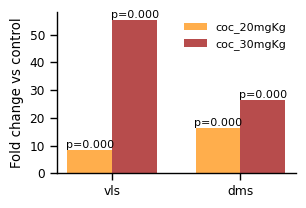

vls: coc_20mgKg fold change = 8.48, p=0.0004
vls: coc_30mgKg fold change = 55.23, p=0.0003
dms: coc_20mgKg fold change = 16.48, p=0.0004
dms: coc_30mgKg fold change = 26.45, p=0.0003


In [53]:
# Section-level fold change vs control (note: sections as unit — see mouse-level analysis below)
region_order = ['vls', 'dms']
group_order = ['control', 'coc_20mgKg', 'coc_30mgKg']

fold_changes = {region: {} for region in region_order}
pvals_fc = {region: {} for region in region_order}

for region in region_order:
    region_df = merged_df[merged_df['region'] == region]
    means = region_df.groupby('exp_group')['fraction'].mean()
    for dose in group_order[1:]:
        fold = means[dose] / means['control'] if means['control'] != 0 else np.nan
        fold_changes[region][dose] = fold
        x_control = region_df[region_df['exp_group'] == 'control']['fraction']
        x_dose = region_df[region_df['exp_group'] == dose]['fraction']
        stat, p = stats.mannwhitneyu(x_control, x_dose, alternative='two-sided')
        pvals_fc[region][dose] = p

fig, ax = plt.subplots(figsize=(80 * mm, 55 * mm))
bar_width = 0.35
x = np.arange(len(region_order))
colors = ['#ff8c00', '#990000']
labels = ['coc_20mgKg', 'coc_30mgKg']

for i, dose in enumerate(labels):
    values = [fold_changes[region][dose] for region in region_order]
    ax.bar(x + i*bar_width, values, bar_width, label=dose, color=colors[i], alpha=0.7)
    for j, region in enumerate(region_order):
        p = pvals_fc[region][dose]
        ax.text(x[j] + i*bar_width, values[j], f'p={p:.3f}', ha='center', va='bottom', fontsize=8)

ax.set_xticks(x + bar_width/2)
ax.set_xticklabels(region_order)
ax.set_ylabel('Fold change vs control')
ax.legend(fontsize=8, frameon=False)
sns.despine()
plt.tight_layout()

fig_path = '../output/cFos/fold_change_vs_control_by_region'
plt.savefig(f'{fig_path}.pdf', dpi=300, bbox_inches='tight')
plt.savefig(f'{fig_path}.png', dpi=300, bbox_inches='tight')
plt.show()

for region in region_order:
    for dose in labels:
        print(f"{region}: {dose} fold change = {fold_changes[region][dose]:.2f}, p={pvals_fc[region][dose]:.4f}")

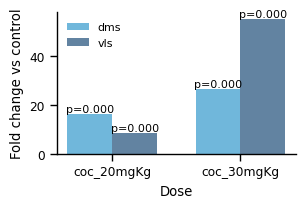

In [54]:
# Section fold change — alternative: x = dose, bars = region
region_colors_fc = {'vls': '#1f4e79', 'dms': '#3399cc'}
region_order_alt = ['dms', 'vls']

fig, ax = plt.subplots(figsize=(80 * mm, 55 * mm))
bar_width = 0.35
x_dose = np.arange(len(labels))   # coc_20mgKg, coc_30mgKg

for i, region in enumerate(region_order_alt):
    values = [fold_changes[region][dose] for dose in labels]
    ax.bar(x_dose + i * bar_width, values, bar_width,
           label=region, color=region_colors_fc[region], alpha=0.7)
    for j, dose in enumerate(labels):
        p = pvals_fc[region][dose]
        ax.text(x_dose[j] + i * bar_width, values[j], f'p={p:.3f}',
                ha='center', va='bottom', fontsize=8)

ax.set_xticks(x_dose + bar_width / 2)
ax.set_xticklabels(labels)
ax.set_ylabel('Fold change vs control')
ax.set_xlabel('Dose')
ax.legend(fontsize=8, frameon=False)
sns.despine()
plt.tight_layout()

fig_path = '../output/cFos/fold_change_vs_control_by_dose'
plt.savefig(f'{fig_path}.pdf', dpi=300, bbox_inches='tight')
plt.savefig(f'{fig_path}.png', dpi=300, bbox_inches='tight')
plt.show()

In [55]:
# Compare fold change distributions between VLS and DMS for each dose using Mann-Whitney U test
group_order = ['control', 'coc_20mgKg', 'coc_30mgKg']
region_order = ['vls', 'dms']

vls_dms_nonparam = []
for dose in group_order[1:]:
    mean_control = {}
    for region in region_order:
        control_df = merged_df[(merged_df['region'] == region) & (merged_df['exp_group'] == 'control')]
        mean_control[region] = control_df['fraction'].mean()
    vls_fold = merged_df[(merged_df['region'] == 'vls') & (merged_df['exp_group'] == dose)].copy()
    dms_fold = merged_df[(merged_df['region'] == 'dms') & (merged_df['exp_group'] == dose)].copy()
    vls_fold['fold_change'] = vls_fold['fraction'] / mean_control['vls'] if mean_control['vls'] != 0 else np.nan
    dms_fold['fold_change'] = dms_fold['fraction'] / mean_control['dms'] if mean_control['dms'] != 0 else np.nan
    stat, p = stats.mannwhitneyu(vls_fold['fold_change'], dms_fold['fold_change'], alternative='two-sided')
    print(f"\nDose: {dose}")
    print(f"VLS fold changes: {vls_fold['fold_change'].values}")
    print(f"DMS fold changes: {dms_fold['fold_change'].values}")
    print(f"Mann-Whitney U test between VLS and DMS fold changes: U={stat:.2f}, p={p:.4f}")
    vls_dms_nonparam.append({'dose': dose, 'U': stat, 'p': p})

save_results = True
if save_results:
    with open('../output/cFos/fold_change_VLS_vs_DMS_stats.txt', 'w') as f:
        for r in vls_dms_nonparam:
            f.write(f"Dose: {r['dose']}, Mann-Whitney U={r['U']:.2f}, p={r['p']:.4f}\n")


Dose: coc_20mgKg
VLS fold changes: [ 4.45100322 13.66066412 19.34234349  9.84098263  4.6741069   7.19949312
  6.42548245  3.902116    6.79748573]
DMS fold changes: [22.21391573 27.55009896 24.42090593 31.6402112   6.42039827 11.42215043
  8.18585979  7.10099464  9.35644115]
Mann-Whitney U test between VLS and DMS fold changes: U=18.00, p=0.0521

Dose: coc_30mgKg
VLS fold changes: [36.93861795 32.89845994 48.4105066  23.96877616 16.62539704 82.78744646
 76.9820567  94.2851942  65.78981247 73.5874293 ]
DMS fold changes: [31.32556937 24.33976733 38.49158186 25.83431444 13.31927895 29.45750665
 29.06839072 26.43617457 22.59698268 23.62431405]
Mann-Whitney U test between VLS and DMS fold changes: U=82.00, p=0.0173


In [ ]:
# Section-level fold change with SEM and individual section points
# (sections as unit — see mouse-level analysis below for correct statistical unit)
region_order = ['dms', 'vls']
dose_order = ['coc_20mgKg', 'coc_30mgKg']
colors = ['#ff8c00', '#990000']

# Control mean per region (section-level)
mean_control = {
    region: merged_df[(merged_df['region'] == region) & (merged_df['exp_group'] == 'control')]['fraction'].mean()
    for region in region_order
}

# Fold change per section
fold_change_data = {region: {dose: [] for dose in dose_order} for region in region_order}
for region in region_order:
    for dose in dose_order:
        dose_df = merged_df[(merged_df['region'] == region) & (merged_df['exp_group'] == dose)]
        fc = dose_df['fraction'] / mean_control[region] if mean_control[region] != 0 else np.nan
        fold_change_data[region][dose] = fc.values

means = np.zeros((len(region_order), len(dose_order)))
sems  = np.zeros((len(region_order), len(dose_order)))
for i, region in enumerate(region_order):
    for j, dose in enumerate(dose_order):
        vals = fold_change_data[region][dose]
        means[i, j] = np.nanmean(vals)
        sems[i, j]  = np.nanstd(vals, ddof=1) / np.sqrt(np.sum(~np.isnan(vals)))

fig, ax = plt.subplots(figsize=(78 * mm, 40 * mm), constrained_layout=True)
bar_width = 0.35
x = np.arange(len(region_order))

for j, dose in enumerate(dose_order):
    bars = ax.bar(x + j*bar_width, means[:, j], bar_width, yerr=sems[:, j],
                  label=dose, facecolor='none', edgecolor=colors[j], alpha=0.7, capsize=5)
    for i, region in enumerate(region_order):
        vals = fold_change_data[region][dose]
        jitter = np.random.normal(0, 0.04, size=len(vals))
        ax.scatter(x[i] + j*bar_width + jitter, vals,
                   facecolors='none', edgecolors=colors[j], marker='o', s=18, alpha=0.6)

ax.set_xticks(x + bar_width/2)
ax.set_xticklabels(region_order)
ax.set_ylabel('Fold change\nvs control')
ax.set_xlabel('Region')
ax.legend(fontsize=8, frameon=False)
sns.despine()

fig_path = '../output/cFos/fold_change_vs_control_by_region_with_SEM'
fig.savefig(f'{fig_path}.pdf', dpi=300, bbox_inches='tight')
fig.savefig(f'{fig_path}.png', dpi=300, bbox_inches='tight')
plt.show()

for i, region in enumerate(region_order):
    for j, dose in enumerate(dose_order):
        print(f"{region}: {dose} mean fold change = {means[i, j]:.2f}, SEM = {sems[i, j]:.2f}")

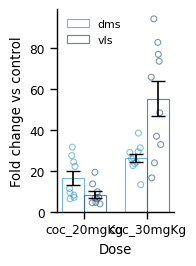

In [64]:
# Section fold change with SEM — alternative: x = dose, bars = region
region_colors_sem = {'vls': '#1f4e79', 'dms': '#3399cc'}
region_order_alt = ['dms', 'vls']

# Reindex means/sems with dose on first axis, region on second (DMS-first order)
means_d = np.zeros((len(dose_order), len(region_order_alt)))
sems_d  = np.zeros((len(dose_order), len(region_order_alt)))
for j, dose in enumerate(dose_order):
    for i, region in enumerate(region_order_alt):
        vals = fold_change_data[region][dose]
        means_d[j, i] = np.nanmean(vals)
        sems_d[j, i]  = np.nanstd(vals, ddof=1) / np.sqrt(np.sum(~np.isnan(vals)))

fig, ax = plt.subplots(figsize=(50 * mm, 70 * mm))
bar_width = 0.35
x_d = np.arange(len(dose_order))

for i, region in enumerate(region_order_alt):
    ax.bar(x_d + i * bar_width, means_d[:, i], bar_width, yerr=sems_d[:, i],
           label=region, facecolor='none', edgecolor=region_colors_sem[region],
           alpha=0.7, capsize=5)
    for j, dose in enumerate(dose_order):
        vals = fold_change_data[region][dose]
        jitter = np.random.normal(0, 0.04, size=len(vals))
        ax.scatter(x_d[j] + i * bar_width + jitter, vals,
                   facecolors='none', edgecolors=region_colors_sem[region],
                   marker='o', s=18, alpha=0.6)

ax.set_xticks(x_d + bar_width / 2)
ax.set_xticklabels(dose_order)
ax.set_ylabel('Fold change vs control')
ax.set_xlabel('Dose')
ax.legend(fontsize=8, frameon=False)
sns.despine()
plt.tight_layout()

fig_path = '../output/cFos/fold_change_vs_control_by_dose_with_SEM'
fig.savefig(f'{fig_path}.pdf', dpi=300, bbox_inches='tight')
fig.savefig(f'{fig_path}.png', dpi=300, bbox_inches='tight')
plt.show()

In [65]:
# Compare fold change distributions between VLS and DMS for each dose using parametric t-tests
group_order = ['control', 'coc_20mgKg', 'coc_30mgKg']
region_order = ['vls', 'dms']

vls_dms_param = []
for dose in group_order[1:]:
    mean_control = {}
    for region in region_order:
        control_df = merged_df[(merged_df['region'] == region) & (merged_df['exp_group'] == 'control')]
        mean_control[region] = control_df['fraction'].mean()
    vls_fold = merged_df[(merged_df['region'] == 'vls') & (merged_df['exp_group'] == dose)].copy()
    dms_fold = merged_df[(merged_df['region'] == 'dms') & (merged_df['exp_group'] == dose)].copy()
    vls_fold['fold_change'] = vls_fold['fraction'] / mean_control['vls'] if mean_control['vls'] != 0 else np.nan
    dms_fold['fold_change'] = dms_fold['fraction'] / mean_control['dms'] if mean_control['dms'] != 0 else np.nan
    t_stat, p = stats.ttest_ind(vls_fold['fold_change'], dms_fold['fold_change'], equal_var=False)
    print(f"\nDose: {dose}")
    print(f"VLS fold changes: {vls_fold['fold_change'].values}")
    print(f"DMS fold changes: {dms_fold['fold_change'].values}")
    print(f"t-test between VLS and DMS fold changes: t={t_stat:.2f}, p={p:.4f}")
    vls_dms_param.append({'dose': dose, 't': t_stat, 'p': p})

save_results = True
if save_results:
    with open('../output/cFos/fold_change_VLS_vs_DMS_parametric_stats.txt', 'w') as f:
        for r in vls_dms_param:
            f.write(f"Dose: {r['dose']}, t-test t={r['t']:.2f}, p={r['p']:.4f}\n")


Dose: coc_20mgKg
VLS fold changes: [ 4.45100322 13.66066412 19.34234349  9.84098263  4.6741069   7.19949312
  6.42548245  3.902116    6.79748573]
DMS fold changes: [22.21391573 27.55009896 24.42090593 31.6402112   6.42039827 11.42215043
  8.18585979  7.10099464  9.35644115]
t-test between VLS and DMS fold changes: t=-2.16, p=0.0519

Dose: coc_30mgKg
VLS fold changes: [36.93861795 32.89845994 48.4105066  23.96877616 16.62539704 82.78744646
 76.9820567  94.2851942  65.78981247 73.5874293 ]
DMS fold changes: [31.32556937 24.33976733 38.49158186 25.83431444 13.31927895 29.45750665
 29.06839072 26.43617457 22.59698268 23.62431405]
t-test between VLS and DMS fold changes: t=3.28, p=0.0083


## Stats table — updated format

| outcome | Design/Test | Unit (n) | Statistic (df) | Effect size (Cohen's d) | 95% CI for d | P (adjusted, Bonferroni ×2) |
|---|---|---:|---|---:|---|---:|
| VLS fold change vs DMS fold change (Dose: 20 mg/kg) | Two‑sample t‑test (two‑tailed, Student's t), equal variances assumed | Control n = 9; Coc 20 mg/kg n = 9 | t(16) = −2.160 | −1.018 | (−1.992, −0.016) | p_raw = 0.04629 → p_adj = 0.09258 |
| VLS fold change vs DMS fold change (Dose: 30 mg/kg) | Two‑sample t‑test (two‑tailed, Student's t), equal variances assumed | Control n = 9; Coc 30 mg/kg n = 10 | t(17) = 3.280 | 1.507 | (0.459, 2.522) | p_raw = 0.00442 → p_adj = 0.00883 |

**Notes:**

- P values are two‑tailed. Bonferroni adjustment applied for 2 planned pairwise comparisons (×2). If you used a different family size or correction (Holm, FDR), tell me and I'll update the adjusted p-values.
- Cohen's d computed from reported t using d = t * sqrt(1/n1 + 1/n2).
- 95% CIs for d were obtained by converting the noncentral‑t CI for the noncentrality parameter to d (solver via SciPy).
- If you prefer Hedges' g (small‑sample correction) or a different CI method, I can compute that as well.

In [66]:
# Compute effect sizes and CIs for the parametric pairwise t-tests and print final table
regions = ['vls', 'dms']
groups = ['control', 'coc_20mgKg', 'coc_30mgKg']

rows = []
for region in regions:
    region_df = merged_df[merged_df['region'] == region]
    data = {g: region_df[region_df['exp_group'] == g]['fraction'].values for g in groups}
    f_stat, f_p = stats.f_oneway(*[data[g] for g in groups])
    pairs = [(groups[0], groups[1]), (groups[0], groups[2]), (groups[1], groups[2])]
    pvals = []
    details = []
    for g1, g2 in pairs:
        x1 = data[g1]; x2 = data[g2]
        n1 = len(x1); n2 = len(x2)
        m1 = np.nanmean(x1); m2 = np.nanmean(x2)
        s1 = np.nanstd(x1, ddof=1); s2 = np.nanstd(x2, ddof=1)
        t_stat, p = stats.ttest_ind(x1, x2, equal_var=False, nan_policy='omit')
        se_sq1 = s1*s1 / n1
        se_sq2 = s2*s2 / n2
        denom = se_sq1 + se_sq2
        welch_df = denom**2 / ((se_sq1**2)/(n1-1) + (se_sq2**2)/(n2-1)) if denom != 0 else float('nan')
        pooled_sd = math.sqrt(((n1-1)*s1*s1 + (n2-1)*s2*s2) / (n1 + n2 - 2)) if (n1+n2-2) > 0 else float('nan')
        d = (m1 - m2) / pooled_sd if pooled_sd > 0 else float('nan')
        df_total = n1 + n2 - 2
        J = 1 - (3.0/(4.0*df_total - 1.0)) if df_total > 1 else 1.0
        g = d * J
        var_d = (n1 + n2)/(n1 * n2) + d**2/(2.0 * (n1 + n2))
        se_d = math.sqrt(var_d)
        ci_low = d - 1.96 * se_d
        ci_high = d + 1.96 * se_d
        pvals.append(p)
        details.append({'g1': g1, 'g2': g2, 'n1': n1, 'n2': n2, 't': t_stat, 'df': welch_df,
                        'd': d, 'g': g, 'ci': (ci_low, ci_high), 'p': p})
    adj = multipletests(pvals, method='fdr_bh')[1]
    for i, det in enumerate(details):
        det['p_adj'] = adj[i]
        rows.append({
            'outcome': f"{region.upper()}: {det['g1']} vs {det['g2']}",
            'design_test': "Welch t-test (two-tailed)",
            'unit_n': f"{det['g1']} n={det['n1']}; {det['g2']} n={det['n2']}",
            'statistic': f"t({det['df']:.2f}) = {det['t']:.3f}",
            'effect_size_d': round(det['d'], 3),
            '95_CI_d': (round(det['ci'][0], 3), round(det['ci'][1], 3)),
            'p_adj': round(det['p_adj'], 6)
        })
    eta2 = f_stat * (len(region_df) - len(groups)) / ((len(region_df) - len(groups)) + (len(groups)-1) * f_stat) if len(region_df) > 0 else float('nan')
    rows.append({
        'outcome': f"{region.upper()}: One-way ANOVA",
        'design_test': 'One-way ANOVA',
        'unit_n': ', '.join([f"{g} n={len(data[g])}" for g in groups]),
        'statistic': f"F = {f_stat:.3f}, p = {f_p:.4f}",
        'effect_size_d': round(eta2, 3),
        '95_CI_d': ('-', '-'),
        'p_adj': round(f_p, 6)
    })

cols = ['outcome', 'design_test', 'unit_n', 'statistic', 'effect_size_d', '95_CI_d', 'p_adj']
print('| ' + ' | '.join(cols) + ' |')
print('| ' + ' | '.join(['---']*len(cols)) + ' |')
for r in rows:
    ci = r['95_CI_d']
    print(f"| {r['outcome']} | {r['design_test']} | {r['unit_n']} | {r['statistic']} | {r['effect_size_d']} | ({ci[0]}, {ci[1]}) | {r['p_adj']} |")

| outcome | design_test | unit_n | statistic | effect_size_d | 95_CI_d | p_adj |
| --- | --- | --- | --- | --- | --- | --- |
| VLS: control vs coc_20mgKg | Welch t-test (two-tailed) | control n=9; coc_20mgKg n=9 | t(8.35) = -4.361 | -2.056 | (-3.198, -0.914) | 0.002173 |
| VLS: control vs coc_30mgKg | Welch t-test (two-tailed) | control n=9; coc_30mgKg n=10 | t(9.02) = -6.352 | -2.761 | (-4.018, -1.503) | 0.000395 |
| VLS: coc_20mgKg vs coc_30mgKg | Welch t-test (two-tailed) | coc_20mgKg n=9; coc_30mgKg n=10 | t(9.71) = -5.373 | -2.344 | (-3.513, -1.175) | 0.00052 |
| VLS: One-way ANOVA | One-way ANOVA | control n=9, coc_20mgKg n=9, coc_30mgKg n=10 | F = 30.743, p = 0.0000 | 8.887 | (-, -) | 0.0 |
| DMS: control vs coc_20mgKg | Welch t-test (two-tailed) | control n=9; coc_20mgKg n=9 | t(8.21) = -4.665 | -2.199 | (-3.369, -1.029) | 0.00226 |
| DMS: control vs coc_30mgKg | Welch t-test (two-tailed) | control n=9; coc_30mgKg n=10 | t(9.59) = -12.110 | -5.28 | (-7.185, -3.375) | 1e-06 |
| 

### *Pseudoreplication fix: mouse-level aggregation*

The preceding analyses treat each section as an independent observation. Because multiple sections come from the same animal, sections within a mouse are not independent — this inflates n and violates the assumptions of all tests above.

The correct statistical unit is the **mouse**. Here we average across sections within each mouse × region, then plot and report statistics at that level.

> **Sample sizes:** n = 2 mice per group (control, coc_20mg/kg, coc_30mg/kg). With n=2 per group, standard parametric and non-parametric tests are severely underpowered (Mann-Whitney minimum p = 0.5 for equal groups of 2; t-test has only 2 df). Data are shown descriptively with the control spread as a reference backdrop.

In [67]:
# Aggregate section-level fractions to mouse level (correct statistical unit)
mouse_df = (
    merged_df
    .groupby(['subject_id', 'exp_group', 'region'], as_index=False)['fraction']
    .mean()
    .rename(columns={'fraction': 'mean_fraction'})
)

# Report sample sizes
n_per_group = mouse_df[mouse_df['region'] == 'vls'].groupby('exp_group')['subject_id'].count().rename('n_mice')
print("N (mice) per group:")
print(n_per_group)
print()

# List mice per group
for group, grp_df in mouse_df[mouse_df['region'] == 'vls'].groupby('exp_group'):
    print(f"{group}: {sorted(grp_df['subject_id'].tolist())}")

mouse_df.head(12)

N (mice) per group:
exp_group
coc_20mgKg    2
coc_30mgKg    2
control       2
Name: n_mice, dtype: int64

coc_20mgKg: ['c577m3', 'wt2']
coc_30mgKg: ['c577m11', 'wt3']
control: ['neg1', 'wt1']


,subject_id,exp_group,region,mean_fraction
0,c577m11,coc_30mgKg,dls,0.019962
1,c577m11,coc_30mgKg,dms,0.043139
2,c577m11,coc_30mgKg,vls,0.023642
3,c577m11,coc_30mgKg,vms,0.021437
4,c577m3,coc_20mgKg,dls,0.012579
5,c577m3,coc_20mgKg,dms,0.038046
6,c577m3,coc_20mgKg,vls,0.007862
7,c577m3,coc_20mgKg,vms,0.014222
8,neg1,control,dls,0.000900
9,neg1,control,dms,0.001077


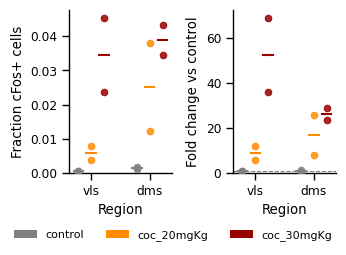

Mouse-level data (n=2 per group — descriptive only):

VLS:
  control (neg1): fraction=0.0007, FC=1.08x
  control (wt1): fraction=0.0006, FC=0.92x
  coc_20mgKg (c577m3): fraction=0.0079, FC=11.93x
  coc_20mgKg (wt2): fraction=0.0039, FC=5.85x
  coc_30mgKg (c577m11): fraction=0.0236, FC=35.88x
  coc_30mgKg (wt3): fraction=0.0454, FC=68.96x

DMS:
  control (neg1): fraction=0.0011, FC=0.73x
  control (wt1): fraction=0.0019, FC=1.27x
  coc_20mgKg (c577m3): fraction=0.0380, FC=25.65x
  coc_20mgKg (wt2): fraction=0.0122, FC=8.24x
  coc_30mgKg (c577m11): fraction=0.0431, FC=29.09x
  coc_30mgKg (wt3): fraction=0.0346, FC=23.35x


In [68]:
# Mouse-level: raw fractions (A) and fold change vs control (B) — correct statistical unit
region_order    = ['vls', 'dms']
exp_group_order = ['control', 'coc_20mgKg', 'coc_30mgKg']
palette  = {'control': '#808080', 'coc_20mgKg': '#ff8c00', 'coc_30mgKg': '#990000'}
dodge    = {'control': -0.22, 'coc_20mgKg': 0.0, 'coc_30mgKg': 0.22}

# Fold change relative to control group mean per region
ctrl_mean = (
    mouse_df[mouse_df['exp_group'] == 'control']
    .groupby('region')['mean_fraction'].mean()
)
mouse_df_fc = mouse_df.copy()
mouse_df_fc['fold_change'] = mouse_df_fc.apply(
    lambda r: r['mean_fraction'] / ctrl_mean[r['region']] if ctrl_mean[r['region']] != 0 else np.nan,
    axis=1
)

fig, axes = plt.subplots(1, 2, figsize=(90 * mm, 60 * mm))

panel_cfg = [
    (axes[0], 'mean_fraction', 'Fraction cFos+ cells'),
    (axes[1], 'fold_change',   'Fold change vs control'),
]

for ax, col, ylabel in panel_cfg:
    for group in exp_group_order:
        grp = mouse_df_fc[
            (mouse_df_fc['exp_group'] == group) &
            (mouse_df_fc['region'].isin(region_order))
        ]
        for i, region in enumerate(region_order):
            vals = grp[grp['region'] == region][col].values
            x = i + dodge[group]
            ax.scatter([x] * len(vals), vals,
                       color=palette[group], s=22, zorder=3, alpha=0.85,
                       label=group if i == 0 else '')
            ax.plot([x - 0.08, x + 0.08], [np.nanmean(vals)] * 2,
                    color=palette[group], lw=1.5, zorder=4)
    ax.set_xticks(range(len(region_order)))
    ax.set_xticklabels(region_order)
    ax.set_xlabel('Region')
    ax.set_ylabel(ylabel)
    ax.set_ylim(bottom=0)
    sns.despine(ax=ax)

axes[1].axhline(1, color='gray', ls='--', lw=0.8, zorder=1)

handles = [mpl.patches.Patch(facecolor=palette[g], label=g) for g in exp_group_order]
fig.legend(handles=handles, loc='lower center', ncol=3, fontsize=8,
           frameon=False, bbox_to_anchor=(0.5, -0.08))

plt.tight_layout()

fig_path = '../output/cFos/mouse_level_fractions_and_foldchange'
fig.savefig(f'{fig_path}.pdf', dpi=300, bbox_inches='tight')
fig.savefig(f'{fig_path}.png', dpi=300, bbox_inches='tight')
plt.show()

print("Mouse-level data (n=2 per group — descriptive only):")
for region in region_order:
    print(f"\n{region.upper()}:")
    for group in exp_group_order:
        rows_g = mouse_df_fc[
            (mouse_df_fc['exp_group'] == group) & (mouse_df_fc['region'] == region)
        ][['subject_id', 'mean_fraction', 'fold_change']]
        for _, row in rows_g.iterrows():
            print(f"  {group} ({row['subject_id']}): fraction={row['mean_fraction']:.4f}, FC={row['fold_change']:.2f}x")

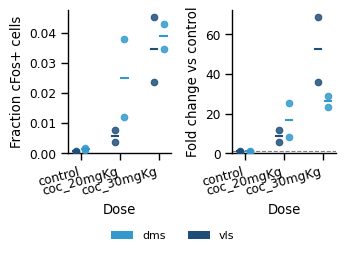

In [69]:
# Mouse-level — alternative: x = dose, VLS and DMS side by side
region_palette_m = {'vls': '#1f4e79', 'dms': '#3399cc'}
dodge_region     = {'vls': -0.12, 'dms': 0.12}
region_order_alt = ['dms', 'vls']

fig, axes = plt.subplots(1, 2, figsize=(90 * mm, 60 * mm))

panel_cfg = [
    (axes[0], 'mean_fraction', 'Fraction cFos+ cells'),
    (axes[1], 'fold_change',   'Fold change vs control'),
]

for ax, col, ylabel in panel_cfg:
    for region in region_order_alt:
        grp = mouse_df_fc[mouse_df_fc['region'] == region]
        for i, dose in enumerate(exp_group_order):
            vals = grp[grp['exp_group'] == dose][col].values
            x = i + dodge_region[region]
            ax.scatter([x] * len(vals), vals,
                       color=region_palette_m[region], s=22, zorder=3, alpha=0.85)
            ax.plot([x - 0.08, x + 0.08], [np.nanmean(vals)] * 2,
                    color=region_palette_m[region], lw=1.5, zorder=4)
    ax.set_xticks(range(len(exp_group_order)))
    ax.set_xticklabels(exp_group_order, rotation=15, ha='right')
    ax.set_xlabel('Dose')
    ax.set_ylabel(ylabel)
    ax.set_ylim(bottom=0)
    sns.despine(ax=ax)

axes[1].axhline(1, color='gray', ls='--', lw=0.8, zorder=1)

handles = [mpl.patches.Patch(facecolor=region_palette_m[r], label=r) for r in region_order_alt]
fig.legend(handles=handles, loc='lower center', ncol=2, fontsize=8,
           frameon=False, bbox_to_anchor=(0.5, -0.08))

plt.tight_layout()

fig_path = '../output/cFos/mouse_level_fractions_and_foldchange_by_dose'
fig.savefig(f'{fig_path}.pdf', dpi=300, bbox_inches='tight')
fig.savefig(f'{fig_path}.png', dpi=300, bbox_inches='tight')
plt.show()